# Phase 1 · Item 4 — MCMC convergence study

This notebook collects the saved burn-in results from `a_study_convergence_mcmc/chain-idf-0.hdf`. The burn-in array contains 200 walkers, 20,000 saved steps, and 20 parameters. The production array in this file contains only one saved step per walker, so the time evolution shown here comes from the saved burn-in.

The separate baseline production diagnostics are included below for context. They belong to the baseline chain, not to this burn-in run.

## What changed during burn-in

Burn-in shows the ensemble moving away from its initial distribution. A resampling boundary is marked at step 10,000; individual walker identities need not remain continuous across it. Initial and final medians are summaries across the walkers, not posterior credible intervals.

For example, the median shadowing factor changes from 0.526 to 0.057, while BG changes from 13.77 to 6.25. These shifts show that initialization matters. They do not prove the final distribution is stationary.

| Parameter | Initial median | Final median |
| --- | --- | --- |
| ylossParam4At2 | 0.99996 | 1.0209 |
| ylossParam4At4 | 2.102 | 1.7116 |
| ylossParam4At6 | 3.0913 | 2.0242 |
| ylossParam4var | 0.55042 | 0.60269 |
| remnant_energy_loss_fraction | 0.50088 | 0.47704 |
| shadowing_factor | 0.52643 | 0.057376 |
| tau_form_mean | 0.62141 | 0.52297 |
| BG | 13.766 | 6.2545 |
| string_source_sigma_x | 0.30331 | 0.2353 |
| string_source_sigma_eta | 0.4432 | 0.50817 |
| stringTransverseShiftFrac | 0.49841 | 0.47549 |
| shear_viscosity_3_eta_over_s_T_kink_in_GeV | 0.22337 | 0.21099 |
| shear_viscosity_3_eta_over_s_low_T_slope_in_GeV | -0.67829 | -0.84569 |
| shear_viscosity_3_eta_over_s_high_T_slope_in_GeV | 0.38452 | 0.68914 |
| shear_viscosity_3_eta_over_s_at_kink | 0.10668 | 0.10937 |
| bulk_viscosity_3_zeta_over_s_max | 0.095711 | 0.088463 |
| bulk_viscosity_3_zeta_over_s_T_peak_in_GeV | 0.20886 | 0.16539 |
| bulk_viscosity_3_zeta_over_s_width_in_GeV | 0.087573 | 0.094337 |
| bulk_viscosity_3_zeta_over_s_lambda_asymm | -0.056928 | -0.25217 |
| eps_switch | 0.36729 | 0.54544 |

### burnin traces

The red line is the median; nested bands enclose central 60% and 90% empirical sample intervals. Traces summarize the ensemble at each displayed step; window summaries pool walkers and steps within each window. These bands describe sample coverage rather than uncertainty of the median.

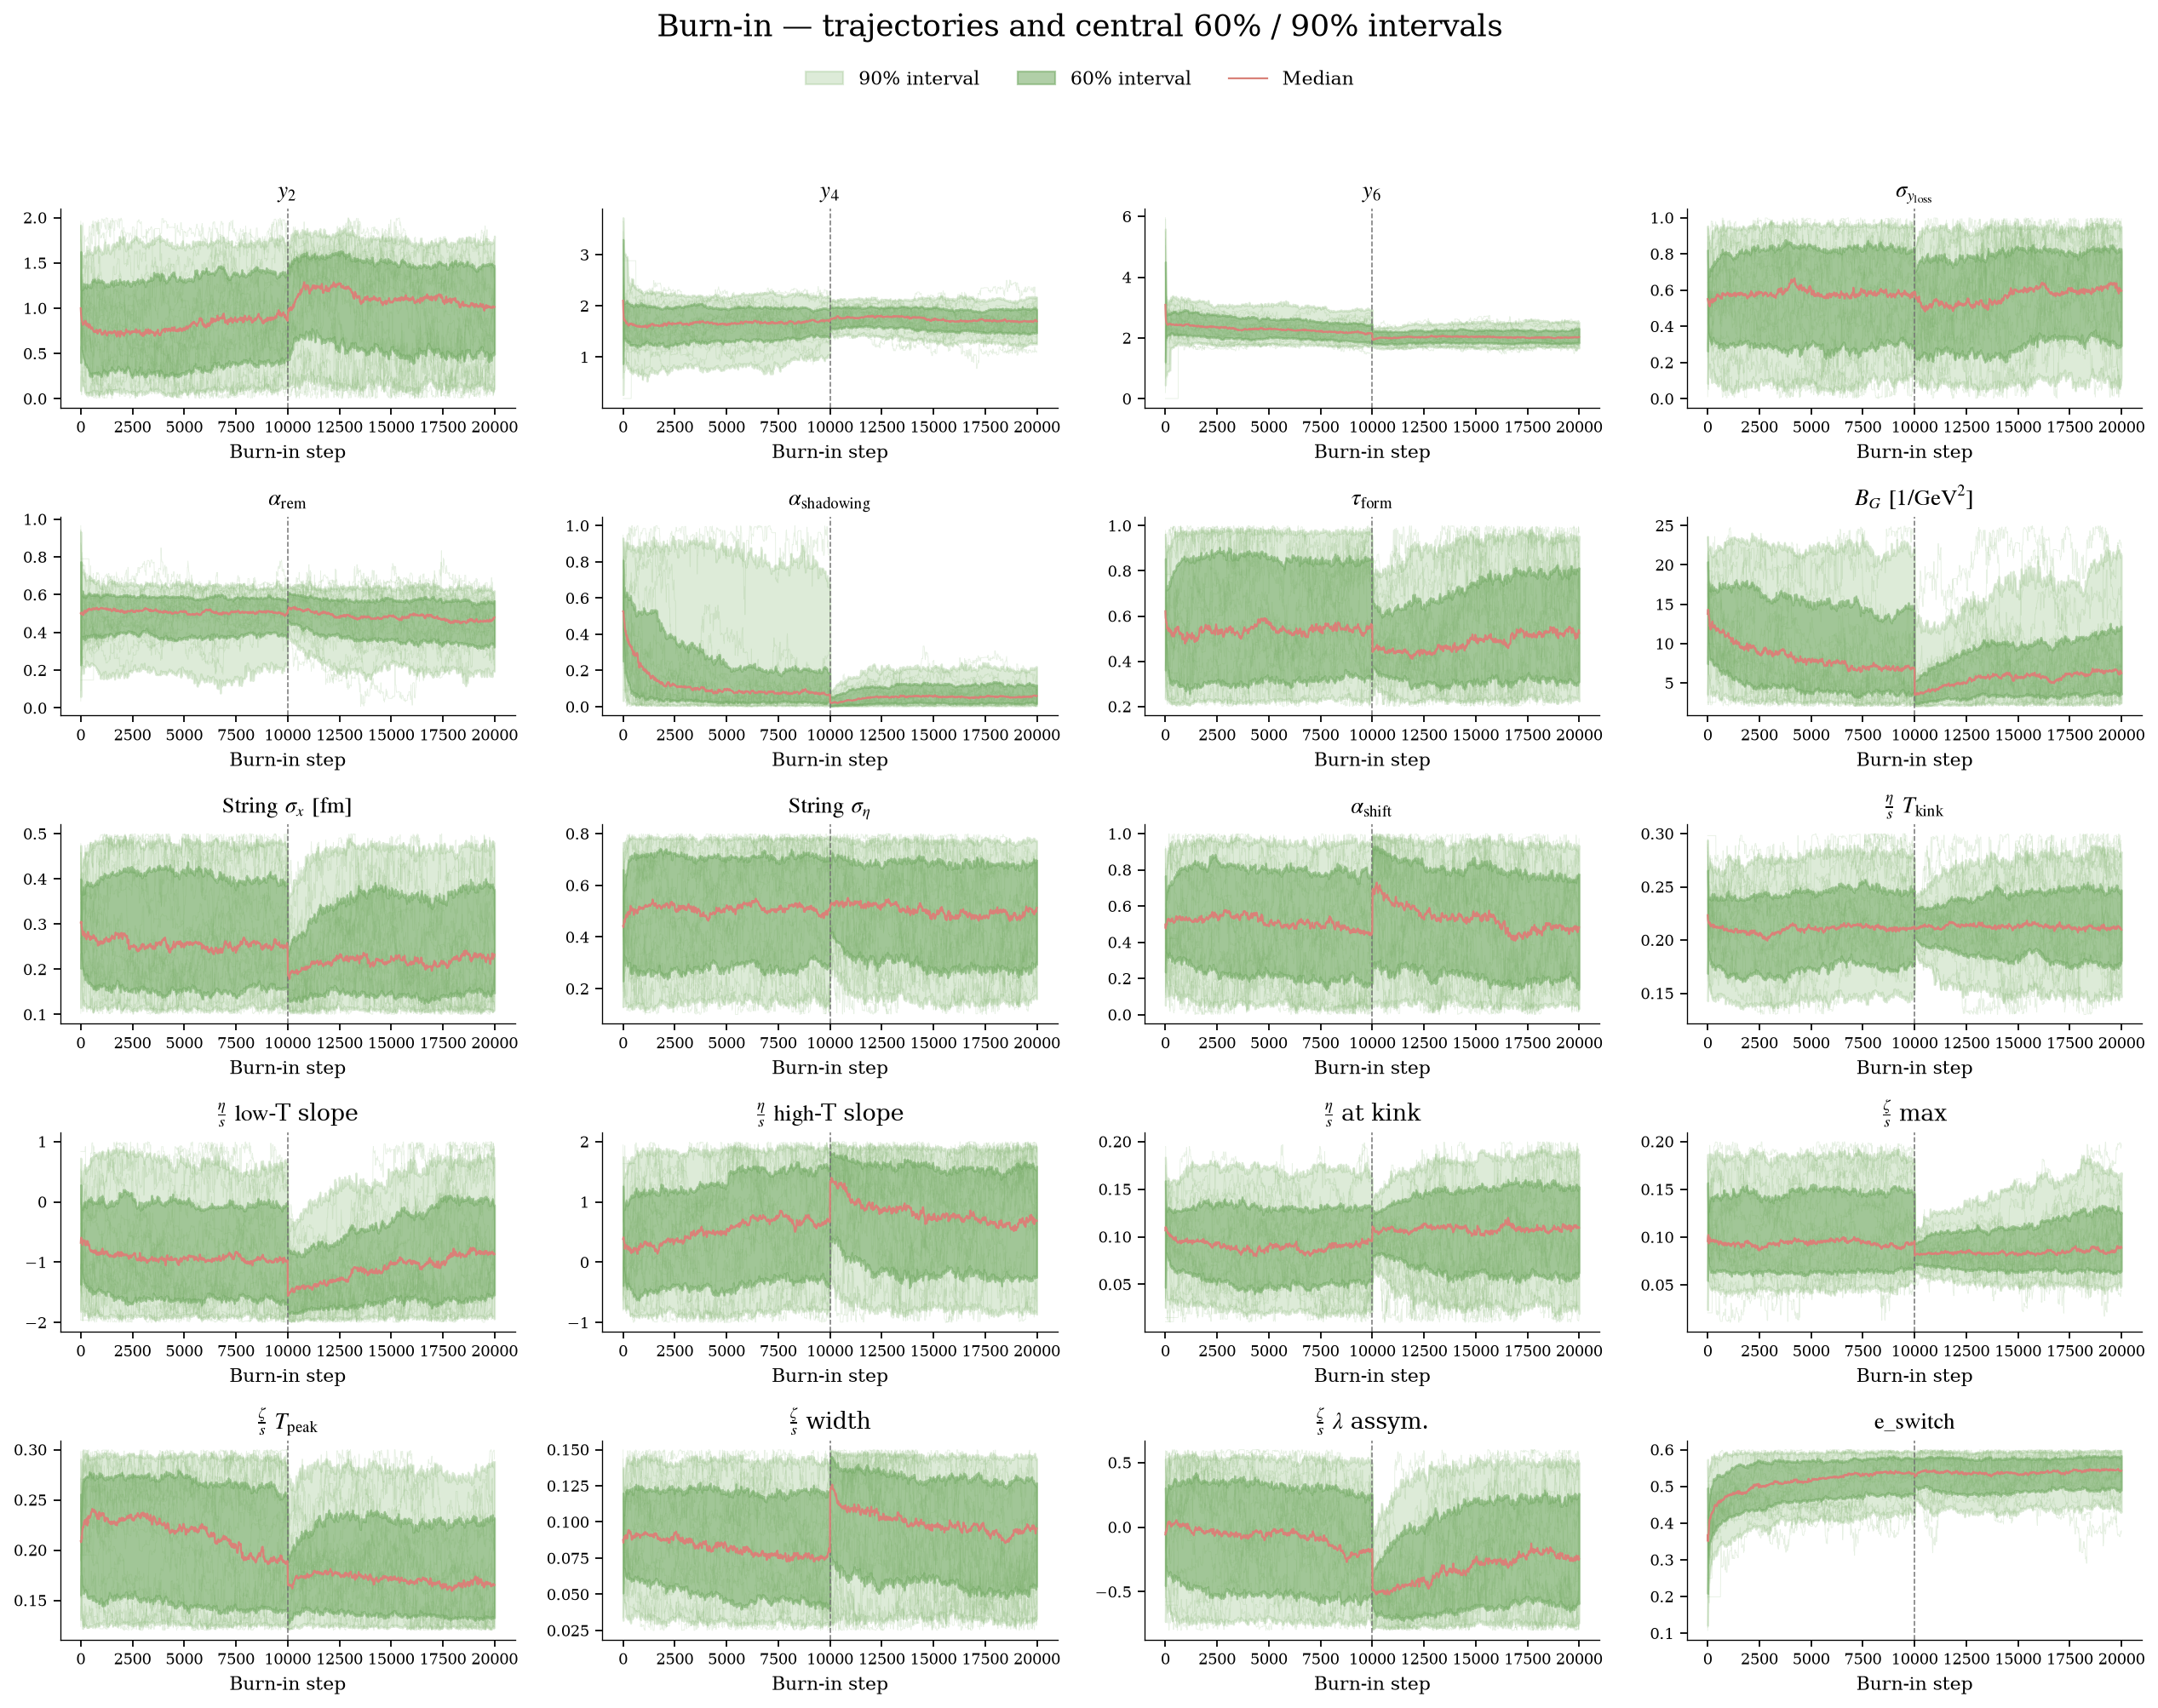

Source: `plots/convergencia/burnin_traces.png`.

### burnin window stability

The red line is the median; nested bands enclose central 60% and 90% empirical sample intervals. Traces summarize the ensemble at each displayed step; window summaries pool walkers and steps within each window. These bands describe sample coverage rather than uncertainty of the median.

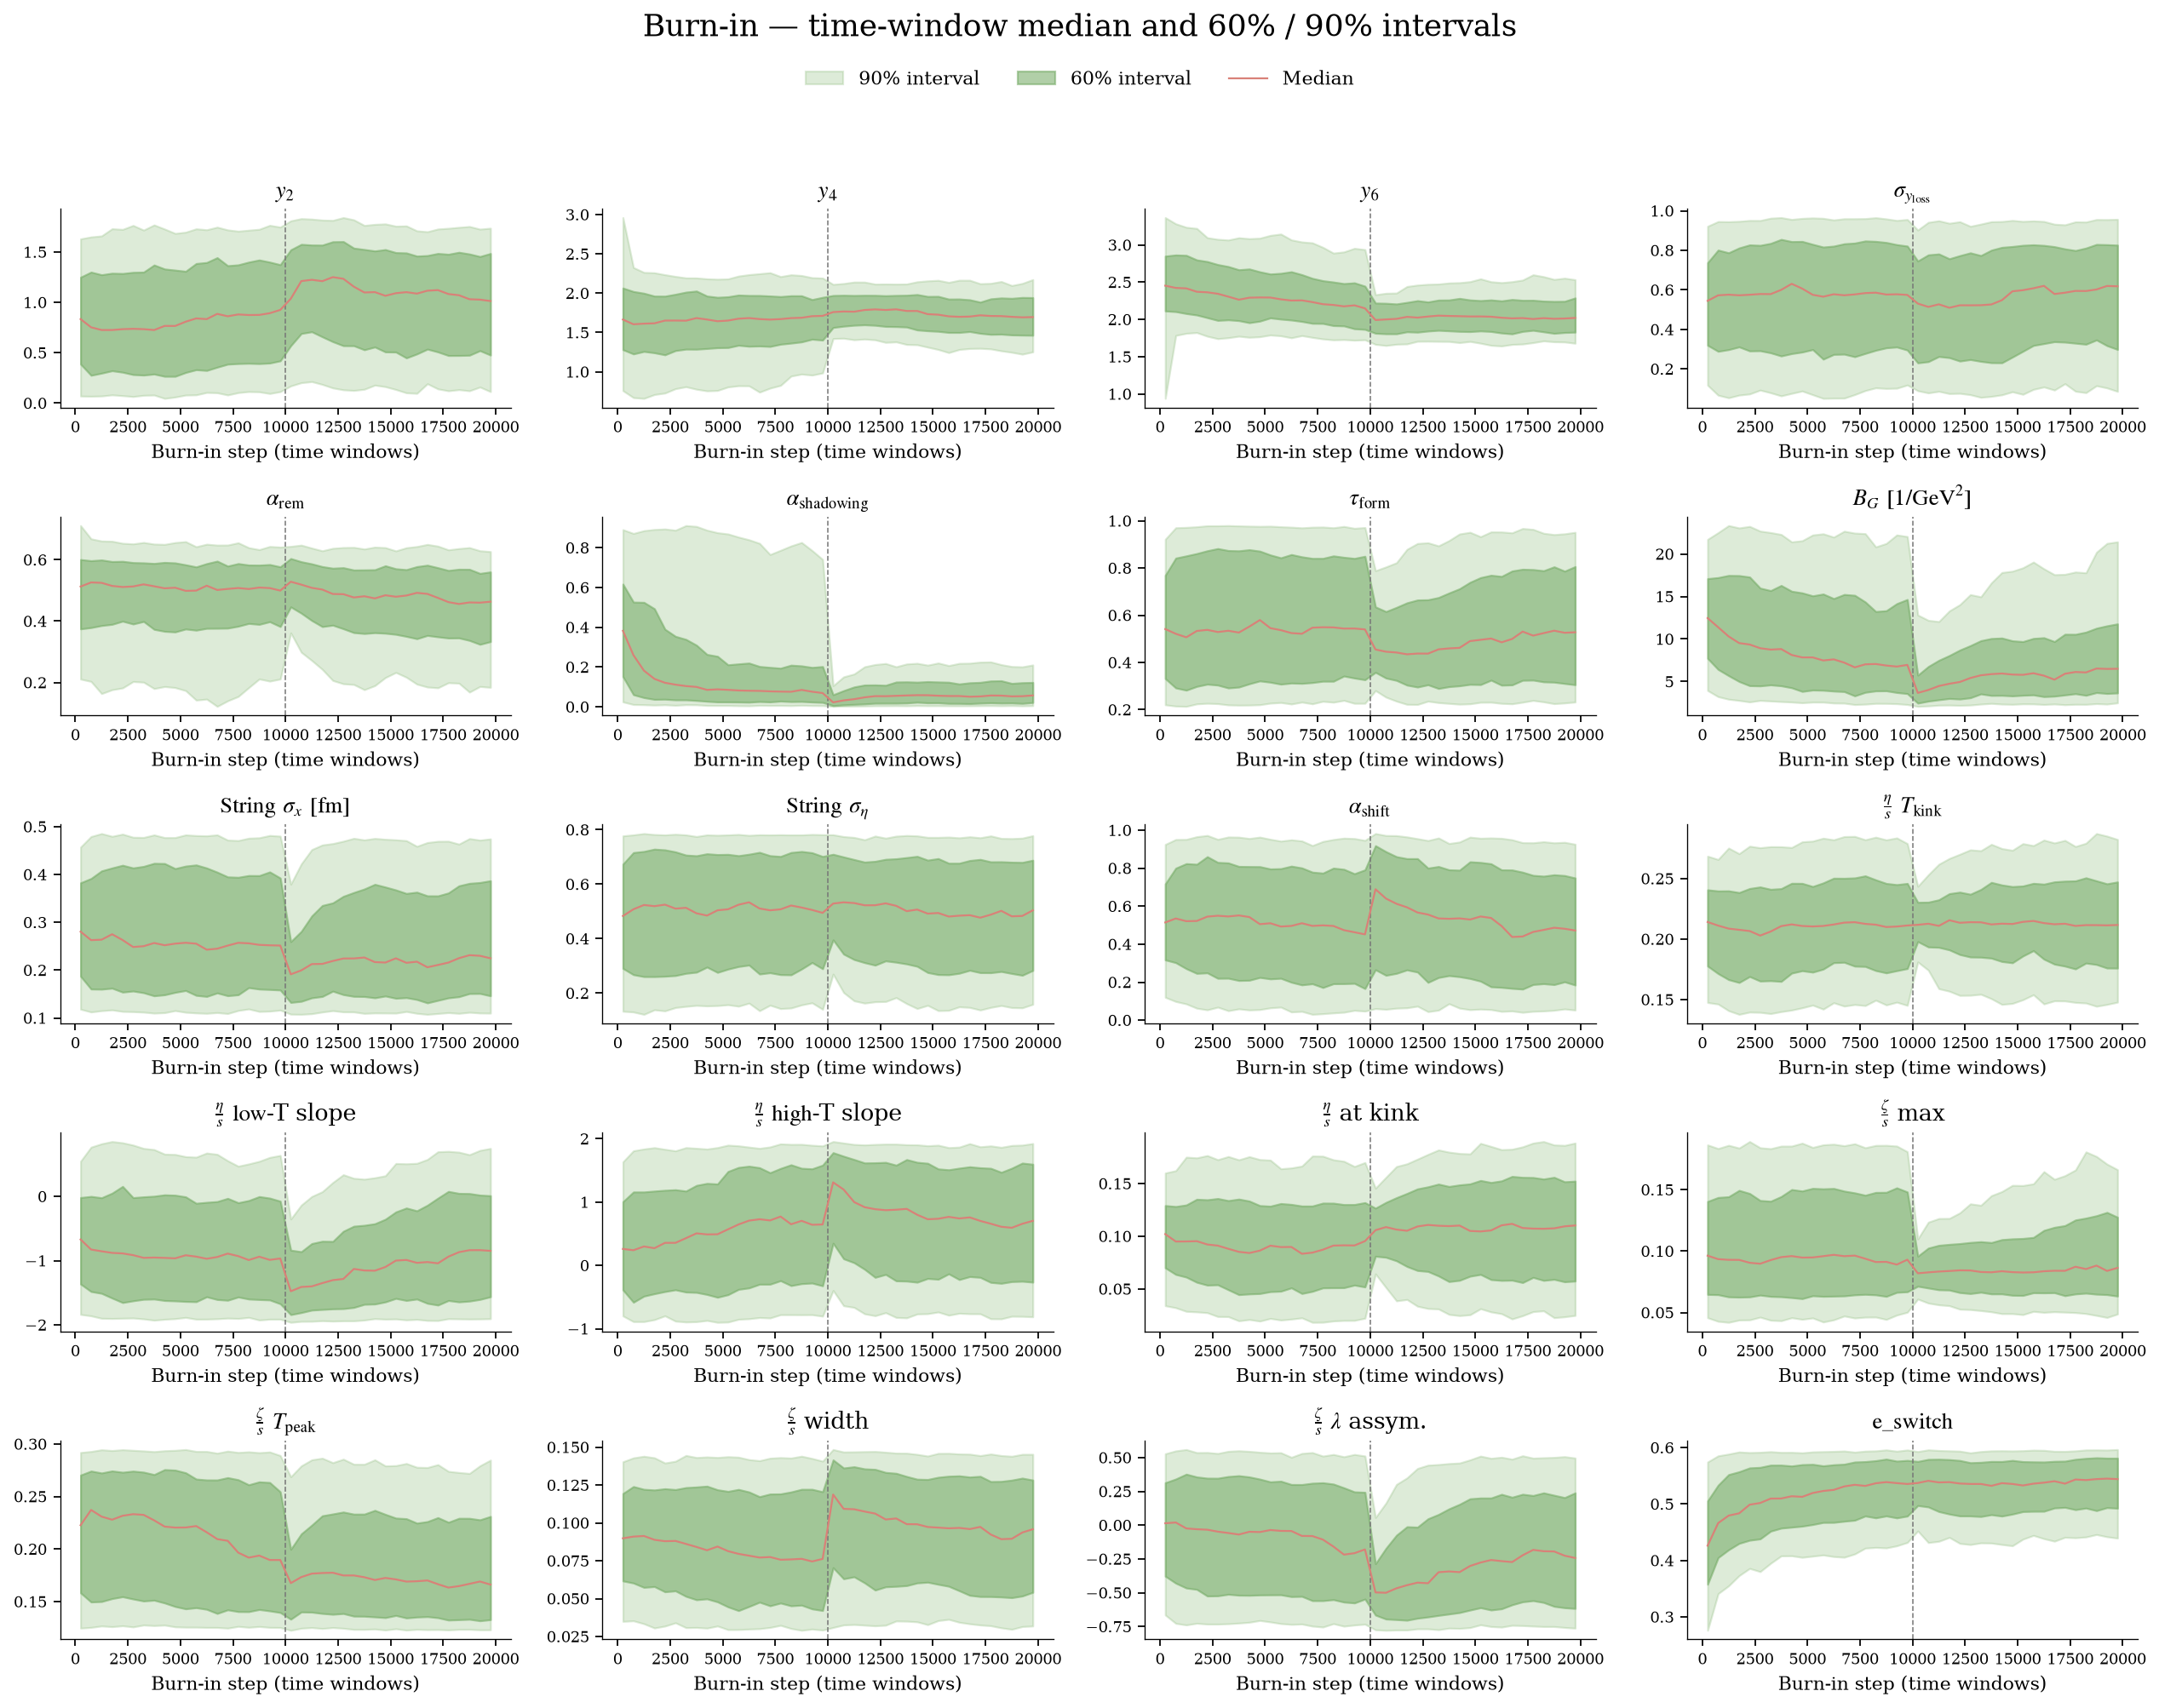

Source: `plots/convergencia/burnin_window_stability.png`.

## Separate baseline production run

For context, the following figures show the baseline production chain: 200 walkers and 50,000 saved steps per walker, with no additional burn-in removal. The red curve is the median and the bands enclose central 60% and 90% empirical sample intervals. Compare the location and width of these bands across time to look for visible drift. These figures belong to a separate run and do not extend the burn-in sequence above.

### walker traces

Tracks the walkers and ensemble distribution over saved steps. Persistent drift or separated regions would call for further sampling. Source: separate baseline production chain.

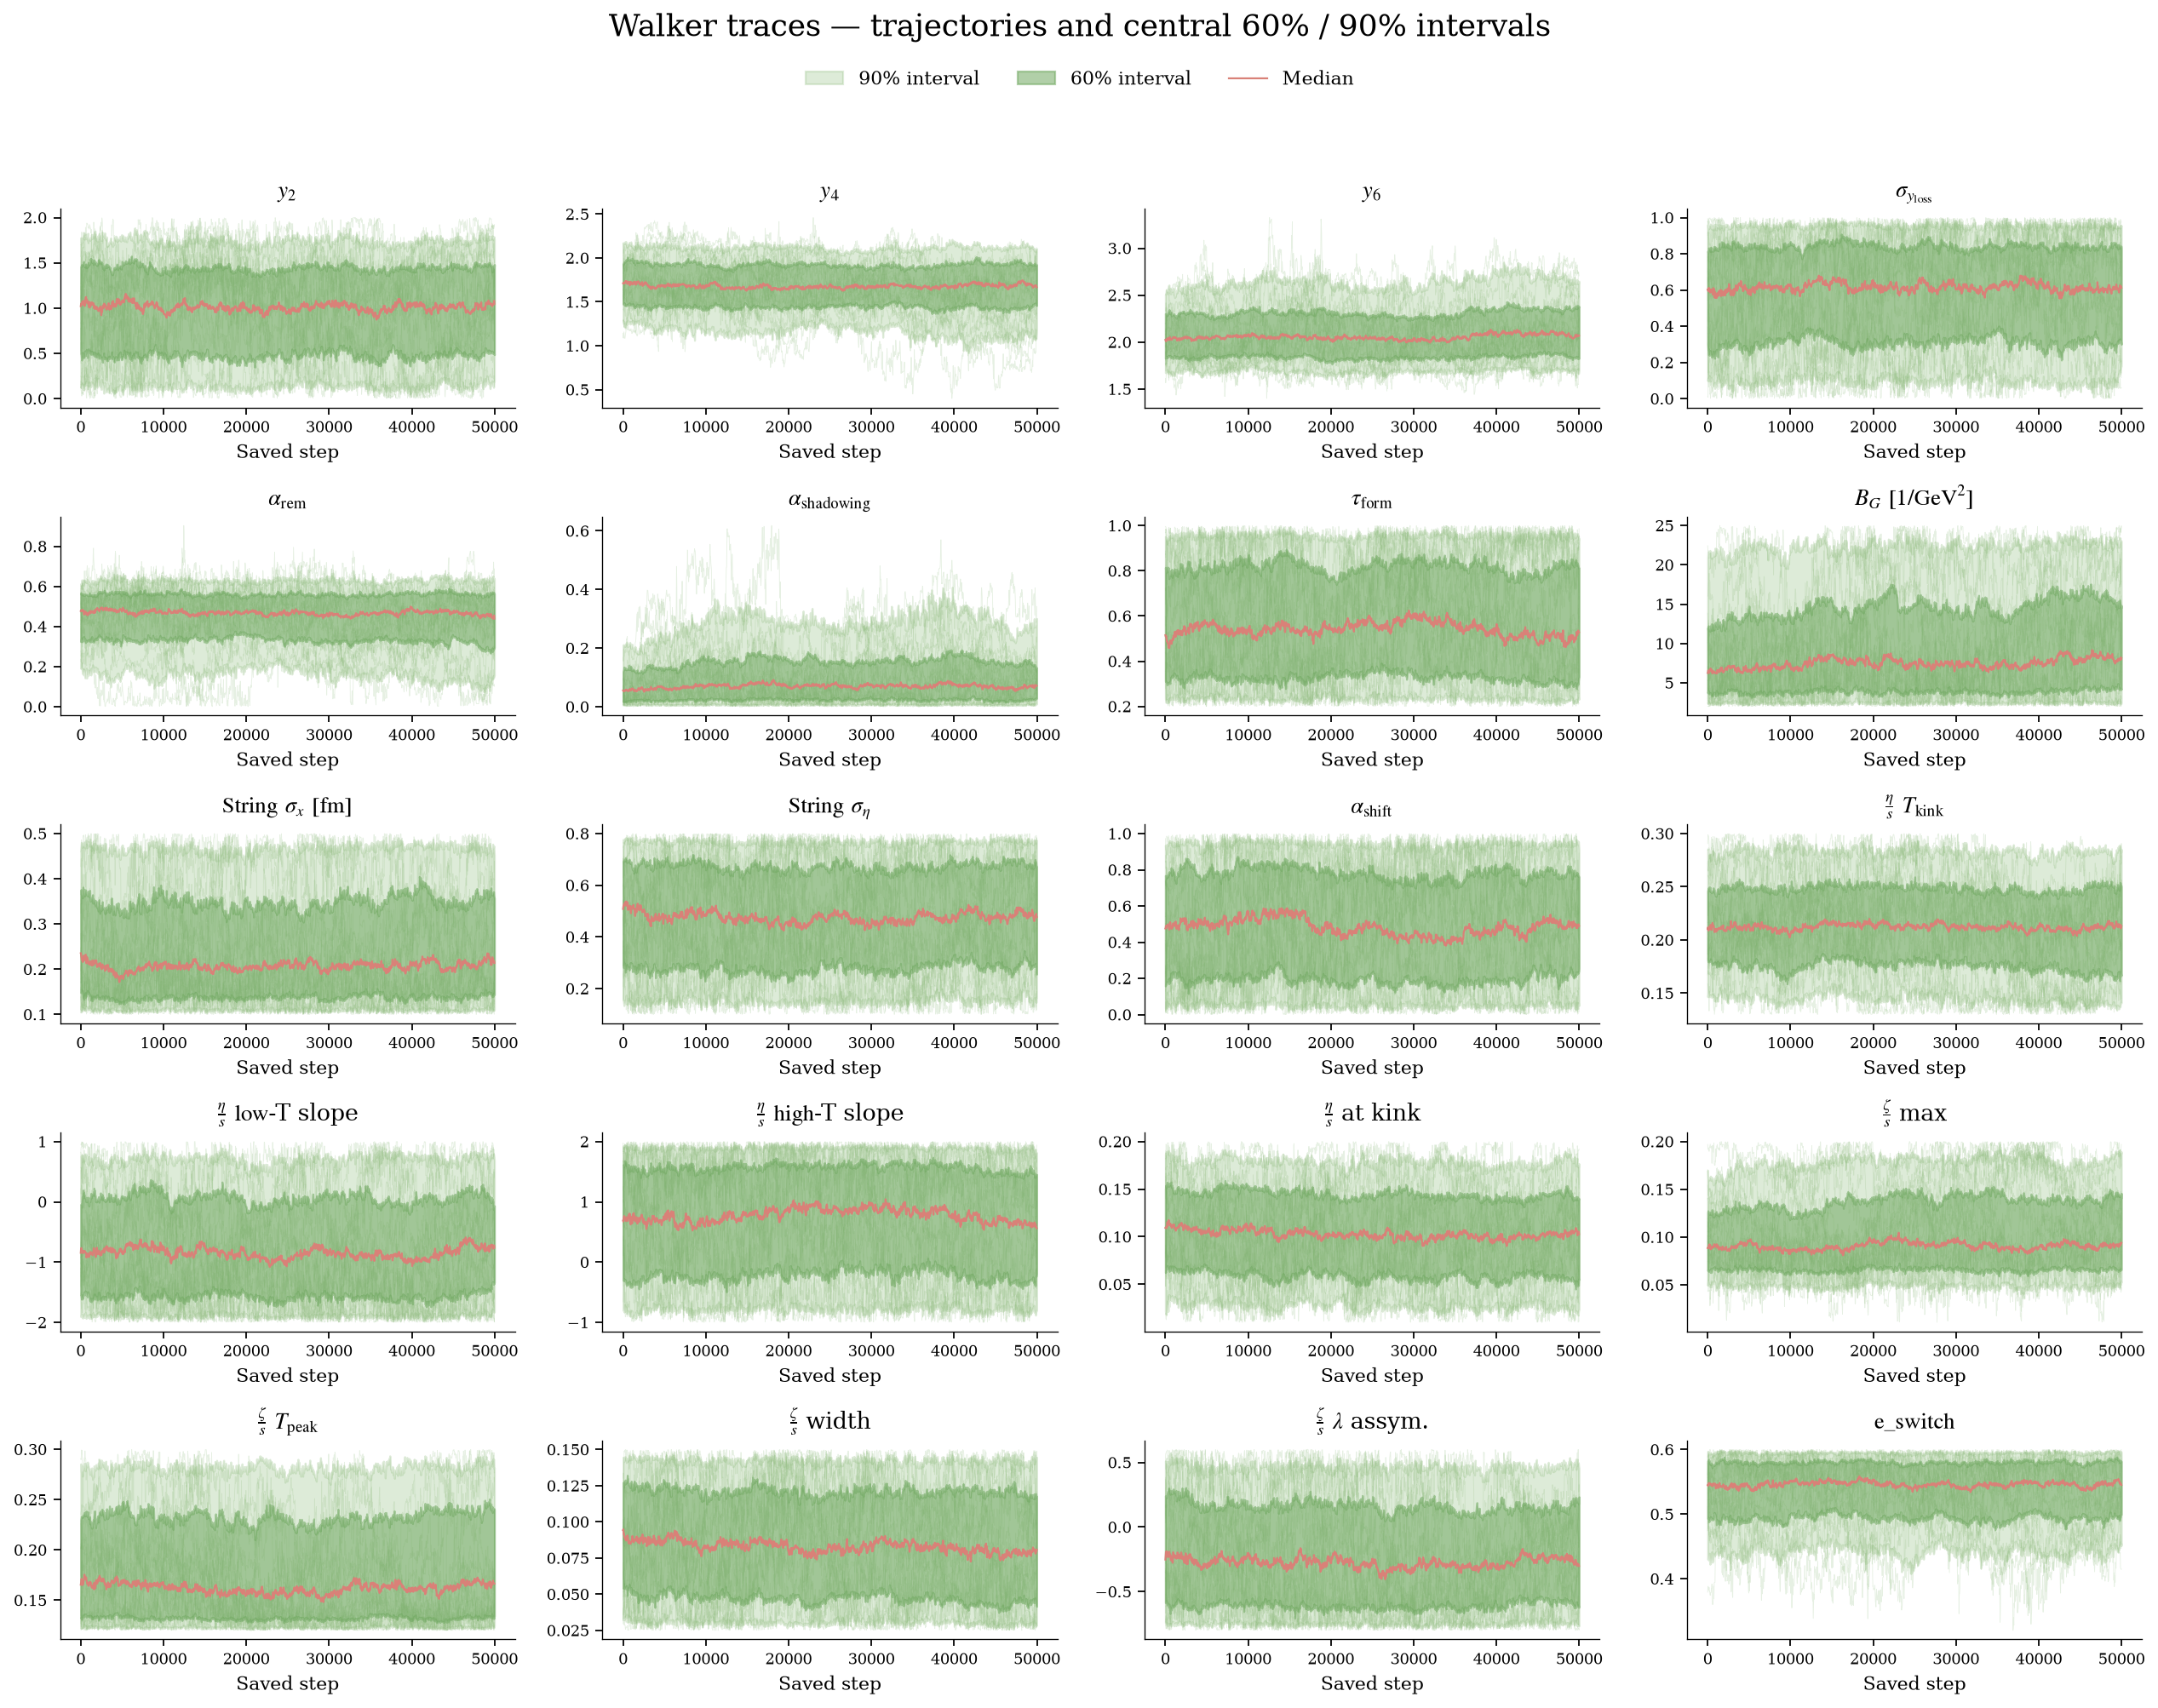

Source: `../a_my_simulation_baseline/plots/convergencia/walker_traces.png`.

### window stability

Compares medians and central 60% / 90% empirical intervals across time windows. These bands describe sample coverage, not uncertainty of the median. Source: separate baseline production chain.

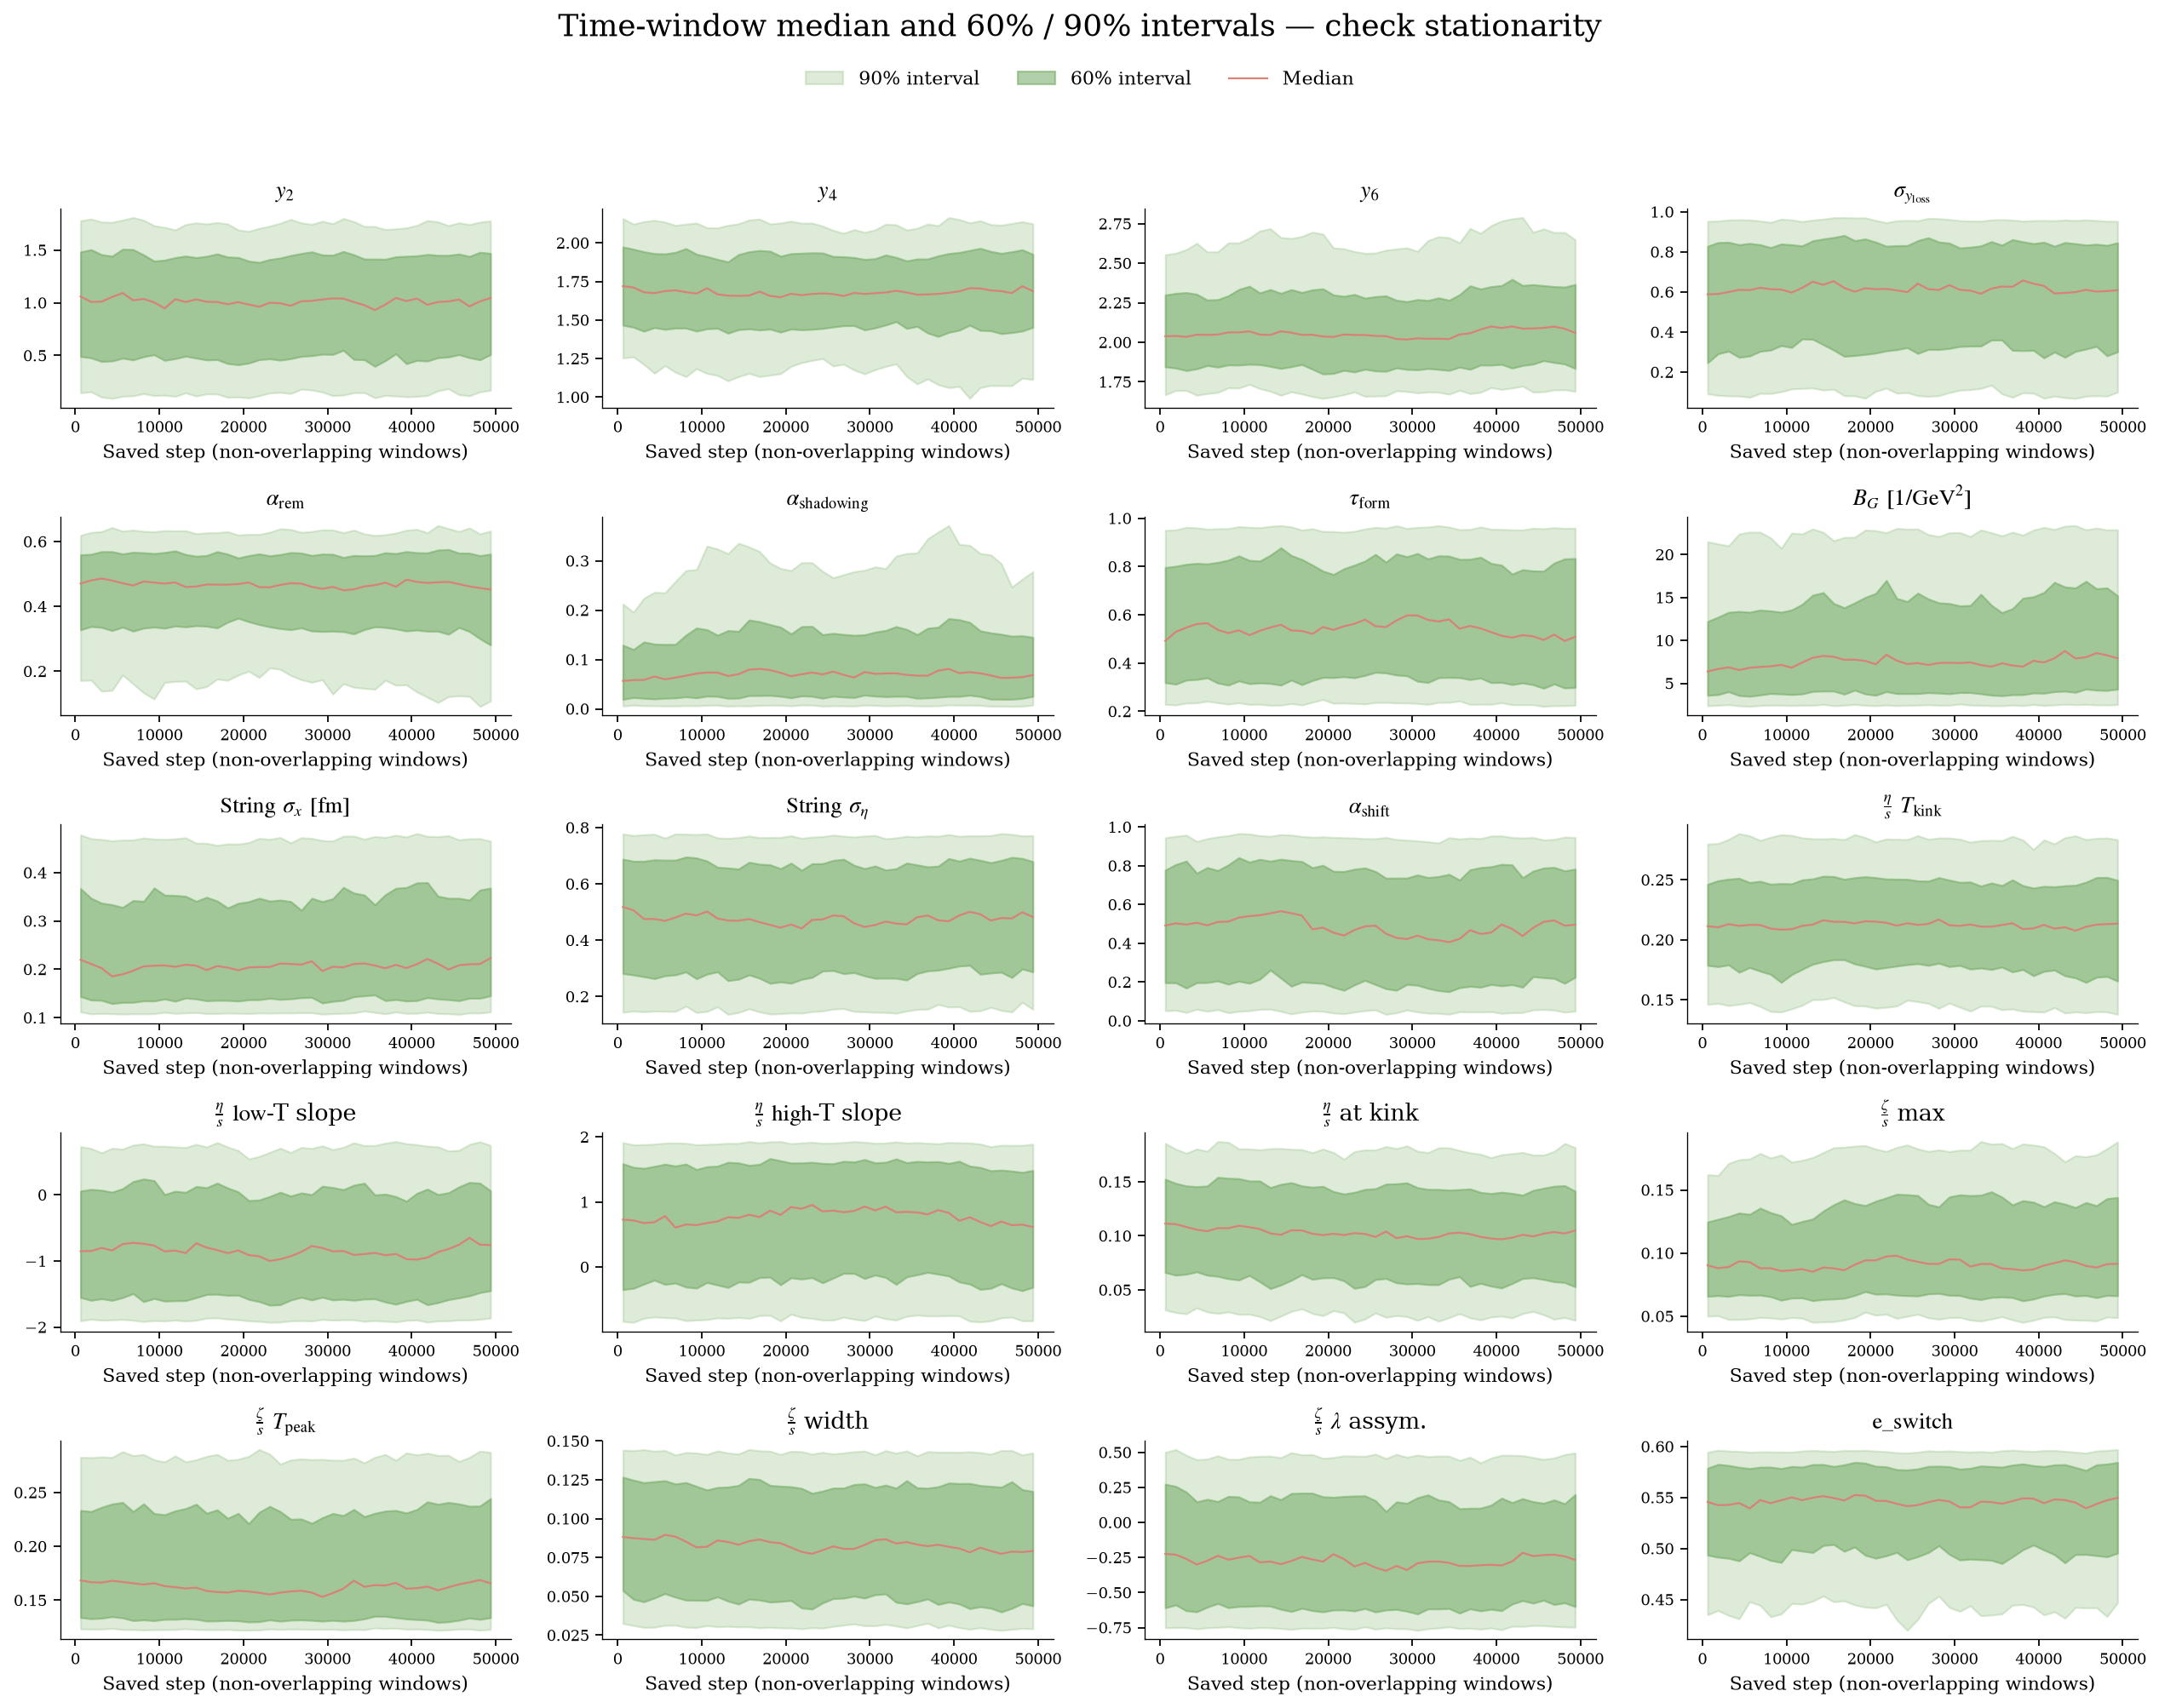

Source: `../a_my_simulation_baseline/plots/convergencia/window_stability.png`.

## Interpretation

The burn-in results show movement away from initialization, including changes in the shadowing factor and BG medians. The 60% and 90% bands show how the ensemble location and spread evolve. Compare late windows for persistent shifts or changes in width. These plots document the interval-based diagnostic study; they do not by themselves establish convergence.

## Available source files

The figures above are embedded in this notebook. The files below remain local source artifacts; publish them alongside the notebook if readers should download them. The `.partial` file is incomplete and is not used for the reported results. Historical absolute paths in JSON metadata refer to earlier directory names.

| File | Bytes |
| --- | --- |
| `chain-idf-0.hdf` | 69196847 |
| `plots/convergencia/burnin_summary.json` | 3566 |
| `plots/convergencia/burnin_traces.pdf` | 2449893 |
| `plots/convergencia/burnin_traces.png` | 2547285 |
| `plots/convergencia/burnin_window_stability.pdf` | 78530 |
| `plots/convergencia/burnin_window_stability.png` | 716569 |

## Check the saved summaries

This cell reads the existing result files. It does not rerun MCMC or retrain the emulator. The report and embedded figures can be read without executing it.

In [1]:
from pathlib import Path
import json

# Run from this study directory, or from its parent mcmc directory.
study = Path.cwd()
if not (study / 'plots').is_dir():
    study = study / 'a_study_convergence_mcmc'
assert (study / 'plots').is_dir(), 'Run from the study or mcmc directory.'
for path in sorted((study / 'plots').rglob('*.json')):
    if path.name.startswith('._'):
        continue
    result = json.loads(path.read_text())
    print(path.relative_to(study))
    for key in ('shape', 'walkers', 'steps', 'burnin', 'thin', 'samples', 'dataset', 'central_intervals', 'interval_quantiles'):
        if key in result:
            print(f'  {key}: {result[key]}')


plots/convergencia/burnin_summary.json
  shape: [200, 20000, 20]
  dataset: burnin
  central_intervals: [0.6, 0.9]
  interval_quantiles: [0.05, 0.2, 0.5, 0.8, 0.95]
